# Car Analytics - Exploratory Data Analysis

This notebook explores the Seaborn MPG dataset before it is loaded into the Django application.

The purpose of the EDA is to:

- Understand the structure of the dataset
- Identify missing or invalid values
- Examine data types
- Explore distributions and relationships between variables
- Prepare a clean dataset for use in the Django application

In [56]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

df = sns.load_dataset("mpg")
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


*Export the raw dataset*

In [57]:
BASE_DIR = Path.cwd().parent

raw_data_path = BASE_DIR / 'data' / 'raw' / 'mpg.csv'


In [3]:
df.shape

(398, 9)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 28.1 KB


## 1. Dataset Overview

The dataset contains 398 car records and 9 columns describing fuel efficiency, engine characteristics, vehicle weight, model year, origin, and vehicle name.

The initial inspection also shows that the `horsepower` column contains 6 missing values.

In [5]:
df.isnull().sum()

mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64

### Missing Values

The dataset contains 6 missing values, all in the `horsepower` column.

No other columns contain missing values. The 6 missing records represent approximately 1.5% of the dataset, so the amount of missing data is relatively small.

The missing `horsepower` values will be handled during the data-cleaning stage rather than removing the affected records immediately.

In [6]:
df.duplicated().sum()

np.int64(0)

### Duplicate Records

The dataset contains 0 duplicated rows.

This means there are no records that are completely identical across all columns.

In [7]:
df.dtypes

mpg             float64
cylinders         int64
displacement    float64
horsepower      float64
weight            int64
acceleration    float64
model_year        int64
origin              str
name                str
dtype: object

### Data Types

The dataset contains 7 numeric columns and 2 categorical columns.

The numeric columns contain vehicle measurements and characteristics such as fuel efficiency, engine size, horsepower, weight, acceleration, and model year.

The `origin` and `name` columns are text-based categorical fields.

The `horsepower` column is stored as `float64` because it contains missing values.

In [8]:
df.describe()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000


### Descriptive Statistics

The descriptive statistics provide an initial overview of the numeric variables in the dataset.

The average fuel efficiency is approximately 23.5 MPG, with values ranging from 9.0 to 46.6 MPG.

Vehicle cylinders range from 3 to 8, with 4 cylinders being the median.

Vehicle weight ranges from 1,613 to 5,140, with an average of approximately 2,970.

The model year values range from 70 to 82, representing model years from 1970 to 1982.

The `horsepower` column has a count of 392 rather than 398, confirming the 6 missing values identified earlier.

In [9]:
df['origin'].value_counts()

origin
usa       249
japan      79
europe     70
Name: count, dtype: int64

In [12]:
df['cylinders'].value_counts().sort_index()

cylinders
3      4
4    204
5      3
6     84
8    103
Name: count, dtype: int64

### Categorical Variable Distribution

The `origin` column contains three categories:

- USA: 249 vehicles
- Japan: 79 vehicles
- Europe: 70 vehicles

The dataset is therefore dominated by vehicles from the USA.

The `cylinders` column contains vehicles with 3, 4, 5, 6, and 8 cylinders. Four-cylinder vehicles are the most common, with 204 records, followed by 8-cylinder vehicles with 103 records and 6-cylinder vehicles with 84 records.

The uneven distribution of these categories is not considered a data-quality issue, but it should be considered when interpreting the analysis.

In [13]:
df['origin'].unique()

<StringArray>
['usa', 'japan', 'europe']
Length: 3, dtype: str

In [14]:
df['cylinders'].unique()

array([8, 4, 6, 3, 5])

### Unique Categories

The `origin` column contains three unique categories: USA, Japan, and Europe.

The `cylinders` column contains five unique values: 3, 4, 5, 6, and 8 cylinders.

These values will later be useful when creating filters and visualizations in the Django application.

In [15]:
df['name'].nunique()

305

In [17]:
df['name'].duplicated().sum()

np.int64(93)

### Vehicle Name Uniqueness

The dataset contains 305 unique vehicle names across 398 records.

There are 93 records where the vehicle name has appeared previously. This does not indicate duplicate records because the complete rows are not identical.

The vehicle name therefore should not be treated as a unique identifier for individual records.

In [18]:
df[df['horsepower'].isna()]

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
32,25.0,4,98.0,NaN,2046,19.0,71,usa,ford pinto
126,21.0,6,200.0,NaN,2875,17.0,74,usa,ford maverick
330,40.9,4,85.0,NaN,1835,17.3,80,europe,renault lecar deluxe
336,23.6,4,140.0,NaN,2905,14.3,80,usa,ford mustang cobra
354,34.5,4,100.0,NaN,2320,15.8,81,europe,renault 18i
374,23.0,4,151.0,NaN,3035,20.5,82,usa,amc concord dl


### Investigating Missing Horsepower

The six missing `horsepower` values belong to individual vehicle records that otherwise contain valid information.

Because the missing values cannot be reliably determined from the dataset alone, the records will be retained rather than removed.

The `horsepower` field will remain missing for these records and will therefore need to allow null values in the Django database model.

This preserves the original data without introducing estimated values.

In [20]:
df[['mpg', 'horsepower', 'weight', 'acceleration']].describe() 

,mpg,horsepower,weight,acceleration
count,398.000000,392.000000,398.000000,398.000000
mean,23.514573,104.469388,2970.424623,15.568090
std,7.815984,38.491160,846.841774,2.757689
min,9.000000,46.000000,1613.000000,8.000000
25%,17.500000,75.000000,2223.750000,13.825000
50%,23.000000,93.500000,2803.500000,15.500000
75%,29.000000,126.000000,3608.000000,17.175000
max,46.600000,230.000000,5140.000000,24.800000


### Numeric Data Validation

The numeric variables were reviewed for potentially invalid values.

The minimum values for MPG, horsepower, weight, and acceleration are all positive and appear plausible for vehicle measurements. No obvious impossible values were identified from the minimum and maximum values.

The `horsepower` statistics are based on 392 non-null observations because 6 records contain missing horsepower values.

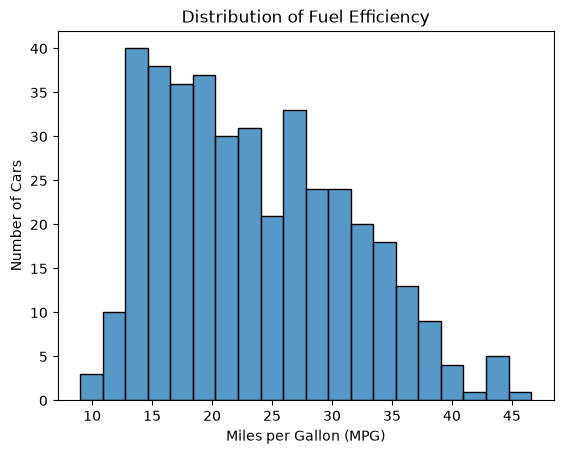

In [28]:
sns.histplot(data=df, x='mpg', bins=20)
plt.title("Distribution of Fuel Efficiency")
plt.xlabel('Miles per Gallon (MPG)')
plt.ylabel('Number of Cars')
plt.show()

### MPG Distribution

The histogram shows the distribution of fuel efficiency across the 398 vehicles.

Most vehicles have fuel efficiency values between approximately 13 and 30 MPG, with the highest concentration occurring in the lower-to-middle MPG range.

There are fewer vehicles with MPG values above 30, with only a small number exceeding 40 MPG.

The distribution appears to be right-skewed, with a longer tail toward higher MPG values.

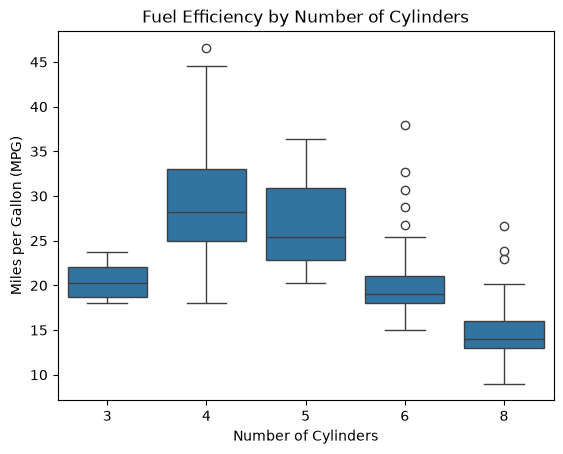

In [33]:
sns.boxplot(data=df, x='cylinders', y='mpg')

plt.title('Fuel Efficiency by Number of Cylinders')
plt.xlabel('Number of Cylinders')
plt.ylabel('Miles per Gallon (MPG)')
plt.show()

### Fuel Efficiency by Number of Cylinders

The boxplot shows a general relationship between cylinder count and fuel efficiency.

Vehicles with 4 and 5 cylinders generally have higher MPG values than vehicles with 6 and 8 cylinders. The 8-cylinder group has the lowest median fuel efficiency.

The 5-cylinder group should be interpreted cautiously because it contains only 3 vehicles.

Several potential outliers are also visible, particularly within the 6- and 8-cylinder groups. These observations will be retained because an outlier is not necessarily an error.

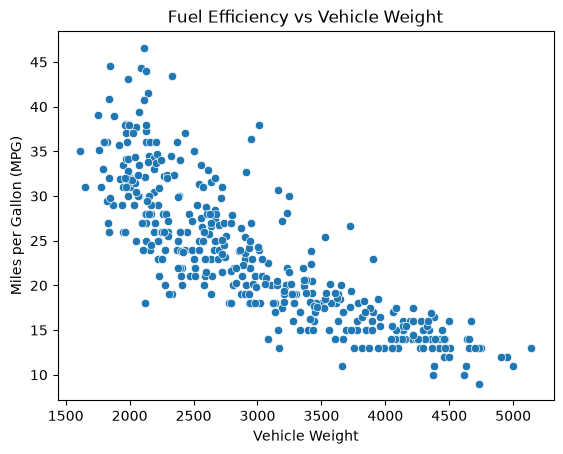

In [39]:
sns.scatterplot(data=df, x='weight', y='mpg')
plt.title('Fuel Efficiency vs Vehicle Weight')
plt.xlabel('Vehicle Weight')
plt.ylabel('Miles per Gallon (MPG)')
plt.show()

### Fuel Efficiency vs Vehicle Weight

The scatter plot shows a strong negative relationship between vehicle weight and fuel efficiency.

Lighter vehicles generally have higher MPG values, while heavier vehicles tend to have lower MPG values.

Although the relationship is not perfectly linear, the overall pattern is clear: as vehicle weight increases, fuel efficiency generally decreases.

There is still variation in MPG at similar vehicle weights, indicating that other vehicle characteristics may also influence fuel efficiency.

In [40]:
df[['weight', 'mpg']].corr()

,weight,mpg
weight,1.000000,-0.831741
mpg,-0.831741,1.000000


### Correlation Between Weight and MPG

The correlation coefficient between vehicle weight and MPG is approximately **-0.83**.

This indicates a strong negative linear relationship between the two variables. In this dataset, heavier vehicles generally tend to have lower fuel efficiency.

The correlation supports the pattern observed in the scatter plot.

Correlation measures association and does not by itself establish causation.

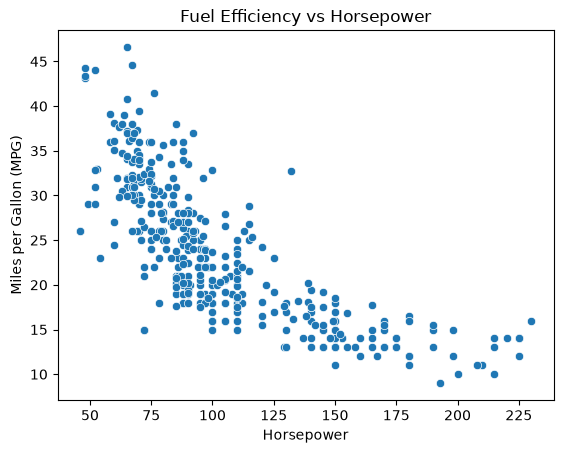

In [52]:
sns.scatterplot(data=df, x='horsepower', y='mpg')
plt.title('Fuel Efficiency vs Horsepower')
plt.xlabel('Horsepower')
plt.ylabel('Miles per Gallon (MPG)')
plt.show()

In [46]:
df[['horsepower', 'mpg']].corr()

,horsepower,mpg
horsepower,1.000000,-0.778427
mpg,-0.778427,1.000000


### Correlation Between Horsepower and MPG

The correlation coefficient between horsepower and MPG is approximately **-0.78**.

This indicates a strong negative linear relationship between the two variables. Vehicles with higher horsepower generally tend to have lower fuel efficiency.

Compared with vehicle weight, which has a correlation of approximately **-0.83** with MPG, horsepower also shows a strong negative association with fuel efficiency.

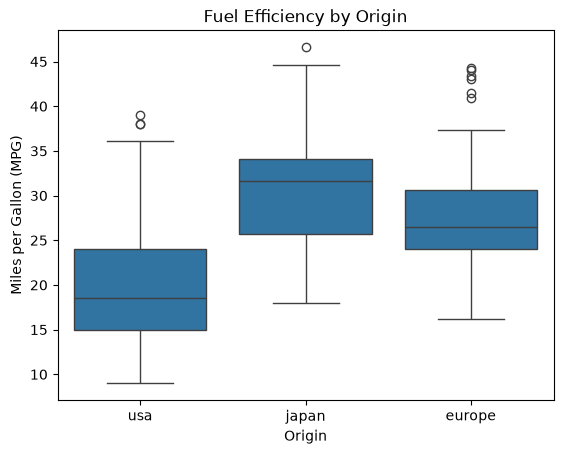

In [51]:
sns.boxplot(data=df, x='origin', y='mpg')
plt.title('Fuel Efficiency by Origin')
plt.xlabel('Origin')
plt.ylabel('Miles per Gallon (MPG)')
plt.show()

### Fuel Efficiency by Origin

The boxplot shows differences in fuel efficiency across the three vehicle origins.

Vehicles from Japan have the highest median MPG, followed by vehicles from Europe, while vehicles from the USA have the lowest median MPG.

The distributions also contain several potential outliers, particularly among the higher-MPG vehicles.

The origin groups have different sample sizes, with the USA representing the largest group. The observed differences may also be related to other vehicle characteristics such as weight, horsepower, cylinder count, and model year.

In [53]:
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [54]:
df.shape

(398, 9)